In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")

df = pd.read_csv("StudentsPerformance.csv")
print(f"Shape: {df.shape[0]} baris × {df.shape[1]} kolom")
df.head()

Shape: 1000 baris × 8 kolom


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [2]:
# Rename kolom agar mudah dipanggil
df = df.rename(columns={
    'race/ethnicity': 'race',
    'parental level of education': 'parent_edu',
    'test preparation course': 'test_prep',
    'math score': 'math',
    'reading score': 'reading',
    'writing score': 'writing'
})

print("=== DATA TYPES ===")
print(df.dtypes)
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())
print(f"\n=== DUPLIKAT === {df.duplicated().sum()}")
print("\n=== DESCRIBE NUMERIK ===")
display(df.describe().round(2))
print("\n=== DISTRIBUSI KATEGORIKAL ===")
for col in ['gender', 'race', 'parent_edu', 'lunch', 'test_prep']:
    print(f"\n{col}:")
    print(df[col].value_counts())

=== DATA TYPES ===
gender        object
race          object
parent_edu    object
lunch         object
test_prep     object
math           int64
reading        int64
writing        int64
dtype: object

=== MISSING VALUES ===
gender        0
race          0
parent_edu    0
lunch         0
test_prep     0
math          0
reading       0
writing       0
dtype: int64

=== DUPLIKAT === 0

=== DESCRIBE NUMERIK ===


,math,reading,writing
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00



=== DISTRIBUSI KATEGORIKAL ===

gender:
gender
female    518
male      482
Name: count, dtype: int64

race:
race
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parent_edu:
parent_edu
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

lunch:
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

test_prep:
test_prep
none         642
completed    358
Name: count, dtype: int64


In [3]:
numeric_cols = ['math', 'reading', 'writing']

central = pd.DataFrame({
    'Mean': df[numeric_cols].mean().round(2),
    'Median': df[numeric_cols].median().round(2),
    'Modus': df[numeric_cols].mode().iloc[0],
    'Diff (Mean-Median)': (df[numeric_cols].mean() - df[numeric_cols].median()).round(2),
})
print(central)

print("\nINTERPRETASI DISTRIBUSI:")
for col in numeric_cols:
    diff = (df[col].mean() - df[col].median()) / df[col].median() * 100
    if abs(diff) < 2:
        shape = "SYMMETRIC (dekat Normal)"
    elif diff > 0:
        shape = f"RIGHT-SKEWED (mean {diff:.1f}% > median)"
    else:
        shape = f"LEFT-SKEWED (mean {diff:.1f}% < median)"
    print(f"  {col:<10}: {shape}")

          Mean  Median  Modus  Diff (Mean-Median)
math     66.09    66.0     65                0.09
reading  69.17    70.0     72               -0.83
writing  68.05    69.0     74               -0.95

INTERPRETASI DISTRIBUSI:
  math      : SYMMETRIC (dekat Normal)
  reading   : SYMMETRIC (dekat Normal)
  writing   : SYMMETRIC (dekat Normal)


In [4]:
dispersion = pd.DataFrame({
    'Range': df[numeric_cols].max() - df[numeric_cols].min(),
    'Variance': df[numeric_cols].var().round(2),
    'Std Dev': df[numeric_cols].std().round(2),
    'Q1': df[numeric_cols].quantile(0.25),
    'Q3': df[numeric_cols].quantile(0.75),
    'IQR': df[numeric_cols].quantile(0.75) - df[numeric_cols].quantile(0.25),
    'CV (%)': (df[numeric_cols].std() / df[numeric_cols].mean() * 100).round(2),
})
print(dispersion)

print("\n=== DETEKSI OUTLIER (IQR method) ===")
for col in numeric_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
    print(f"  {col:<10}: {n_out} outlier (<{Q1-1.5*IQR:.1f} atau >{Q3+1.5*IQR:.1f})")

         Range  Variance  Std Dev     Q1    Q3    IQR  CV (%)
math       100    229.92    15.16  57.00  77.0  20.00   22.94
reading     83    213.17    14.60  59.00  79.0  20.00   21.11
writing     90    230.91    15.20  57.75  79.0  21.25   22.33

=== DETEKSI OUTLIER (IQR method) ===
  math      : 8 outlier (<27.0 atau >107.0)
  reading   : 6 outlier (<29.0 atau >109.0)
  writing   : 5 outlier (<25.9 atau >110.9)


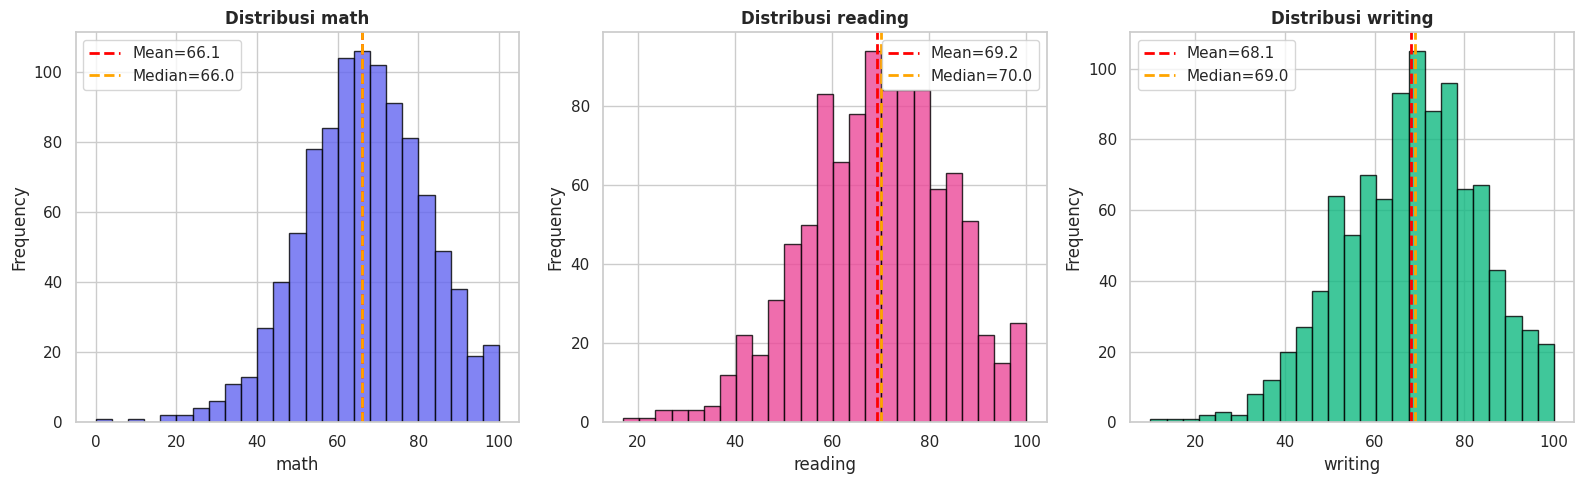

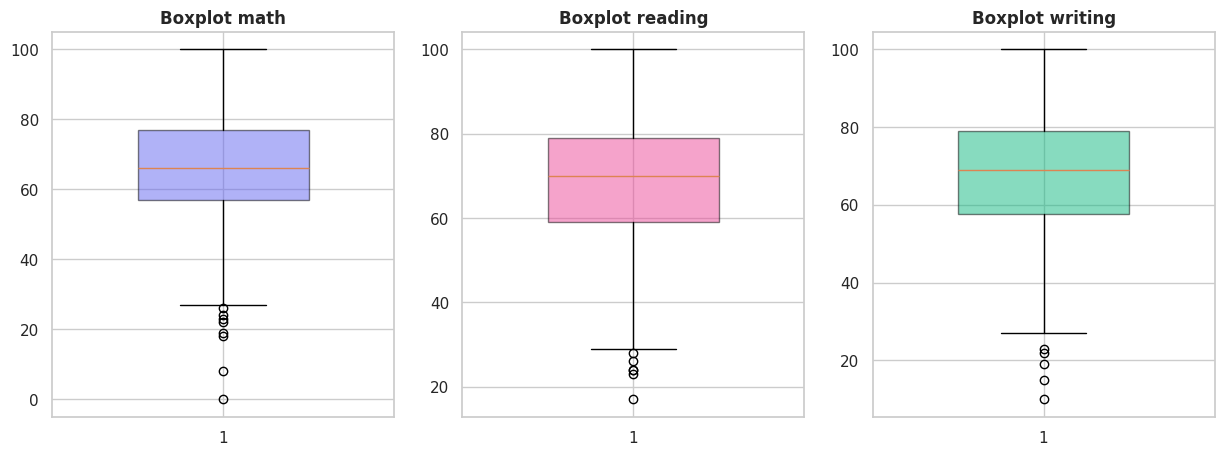

In [5]:
numeric_cols = ['math', 'reading', 'writing']
df['avg_score'] = df[numeric_cols].mean(axis=1).round(2)
colors = ['#6366F1', '#EC4899', '#10B981']

# Histogram + garis mean/median
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, color in zip(axes, numeric_cols, colors):
    ax.hist(df[col], bins=25, color=color, edgecolor='black', alpha=0.8)
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean={df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='orange', linestyle='--', linewidth=2, label=f'Median={df[col].median():.1f}')
    ax.set_title(f'Distribusi {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()
plt.tight_layout()
plt.show()

# Boxplot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, color in zip(axes, numeric_cols, colors):
    bp = ax.boxplot(df[col], patch_artist=True, widths=0.5)
    bp['boxes'][0].set_facecolor(color)
    bp['boxes'][0].set_alpha(0.5)
    ax.set_title(f'Boxplot {col}', fontweight='bold')

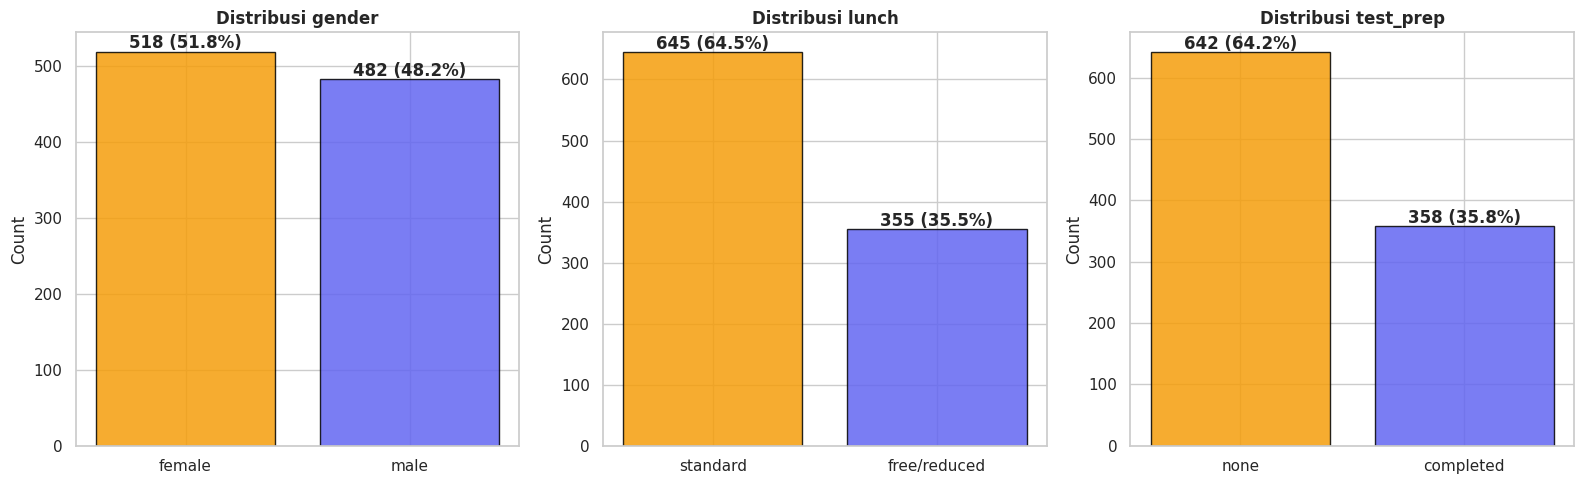

In [6]:
# Countplot kategorikal
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['gender', 'lunch', 'test_prep']):
    counts = df[col].value_counts()
    bars = ax.bar(counts.index, counts.values, color=['#F59E0B', '#6366F1'],
                  edgecolor='black', alpha=0.85)
    ax.set_title(f'Distribusi {col}', fontweight='bold')
    ax.set_ylabel('Count')
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                f'{val} ({val/len(df)*100:.1f}%)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

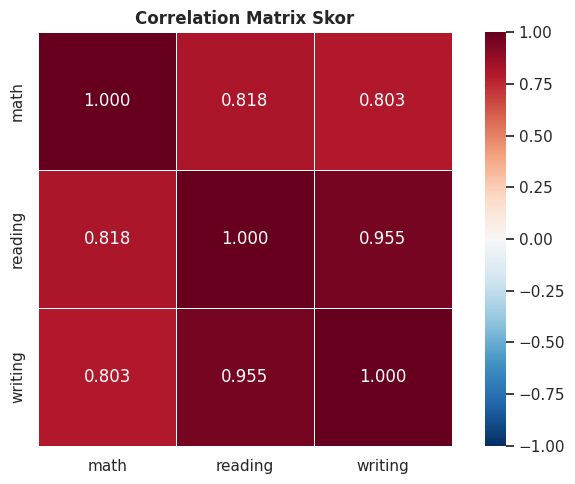

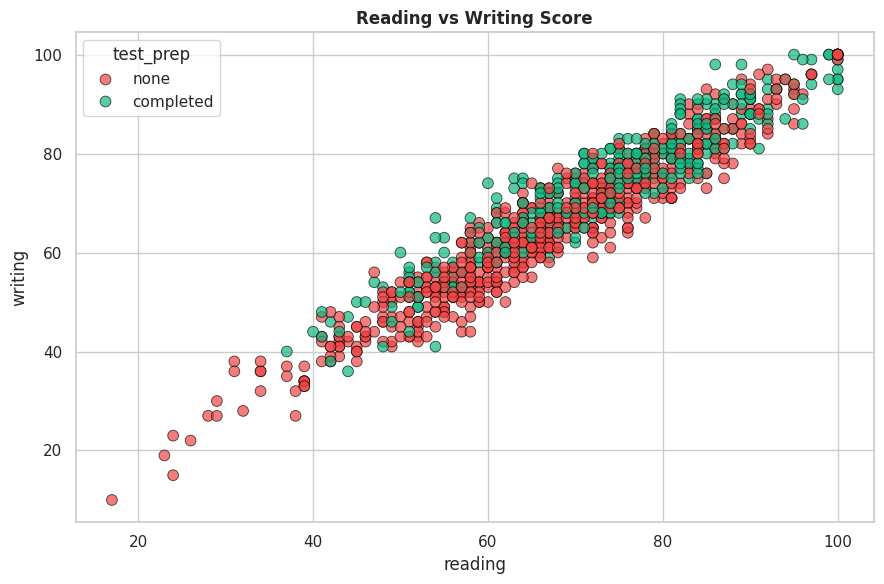

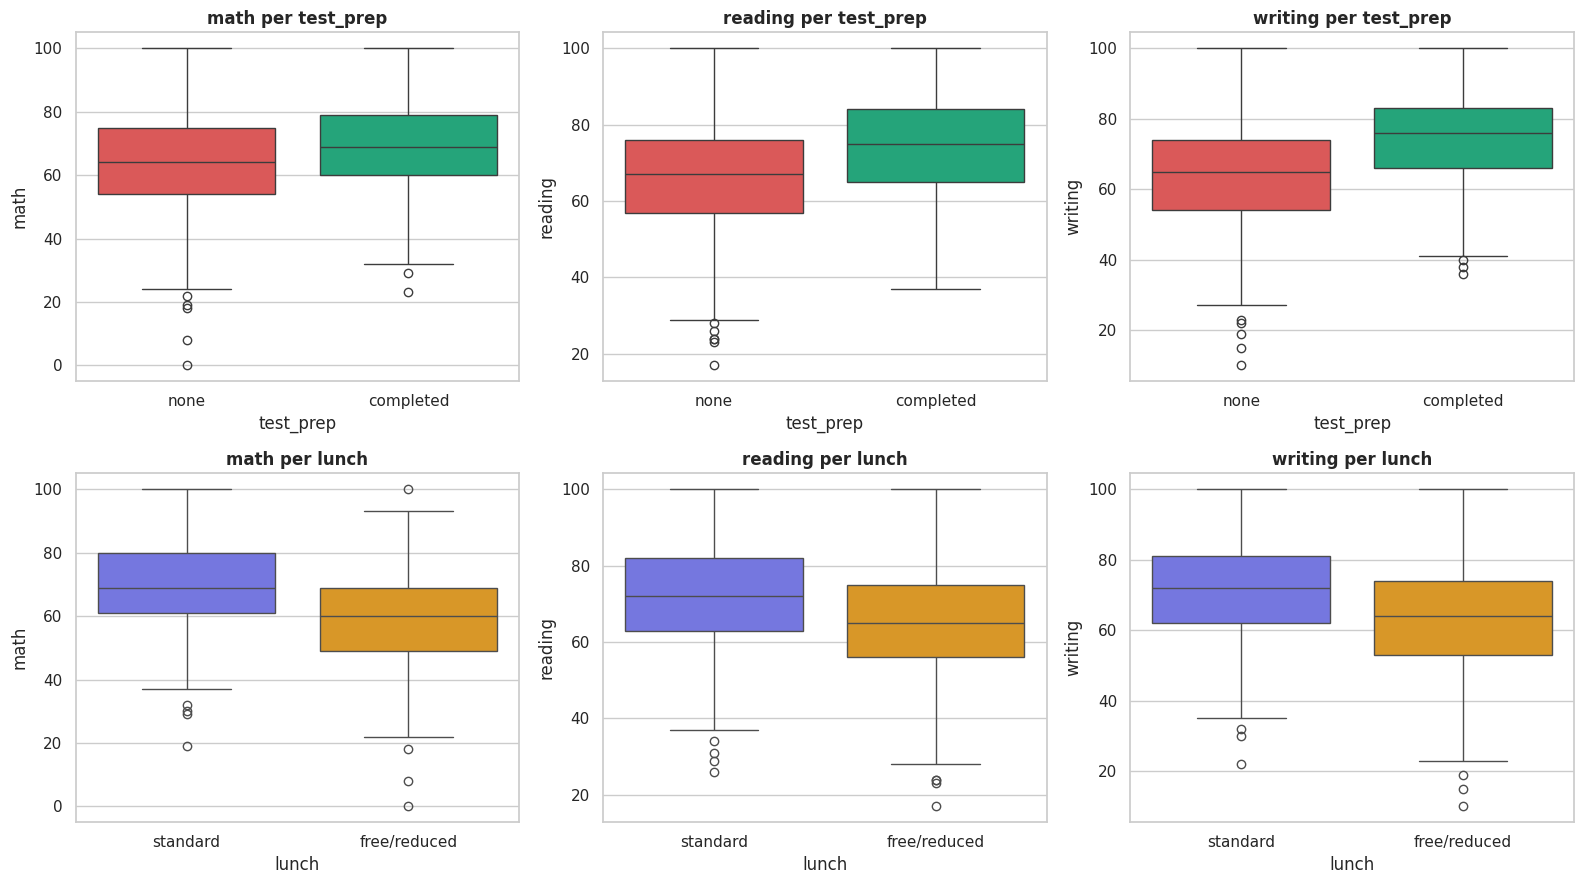

In [7]:
# Heatmap korelasi
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True)
ax.set_title('Correlation Matrix Skor', fontweight='bold')
plt.tight_layout()
plt.show()

# Scatter: reading vs writing, warna per test_prep
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x='reading', y='writing', hue='test_prep',
                palette={'none': '#EF4444', 'completed': '#10B981'},
                s=60, alpha=0.7, edgecolor='black', ax=ax)
ax.set_title('Reading vs Writing Score', fontweight='bold')
plt.tight_layout()
plt.show()

# Grouped boxplot: skor per test_prep dan per lunch
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x='test_prep', y=col, hue='test_prep', legend=False,
                palette={'none': '#EF4444', 'completed': '#10B981'}, ax=axes[0, j])
    axes[0, j].set_title(f'{col} per test_prep', fontweight='bold')
    sns.boxplot(data=df, x='lunch', y=col, hue='lunch', legend=False,
                palette={'standard': '#6366F1', 'free/reduced': '#F59E0B'}, ax=axes[1, j])
    axes[1, j].set_title(f'{col} per lunch', fontweight='bold')
plt.tight_layout()
plt.show()

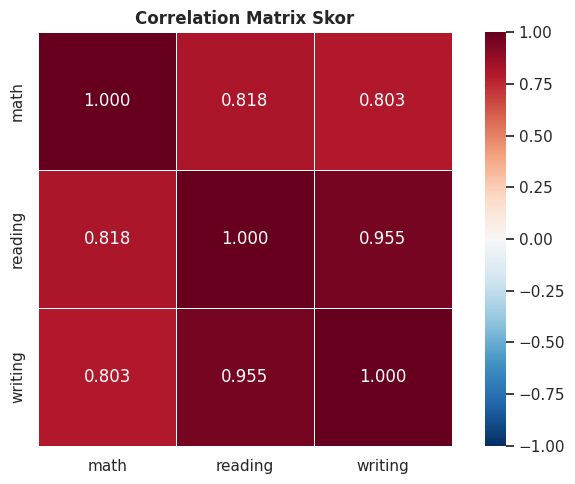

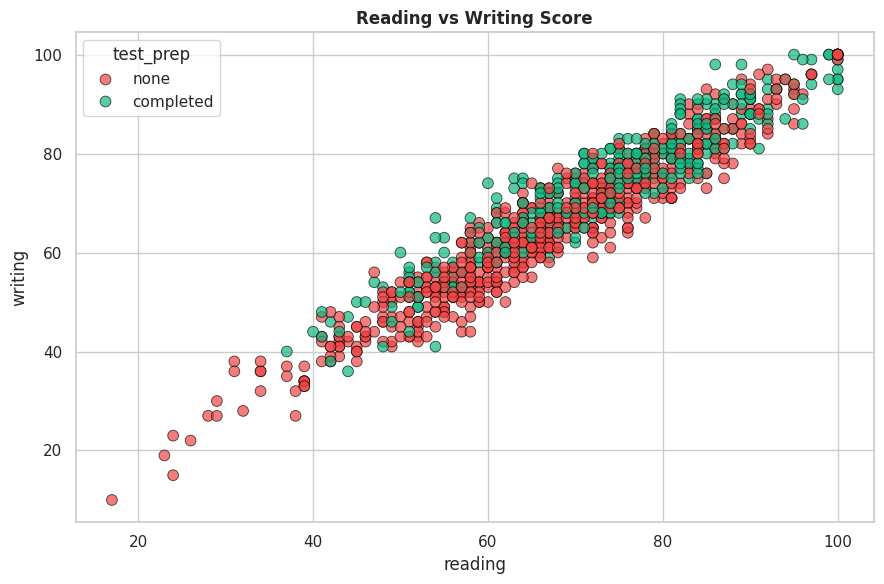

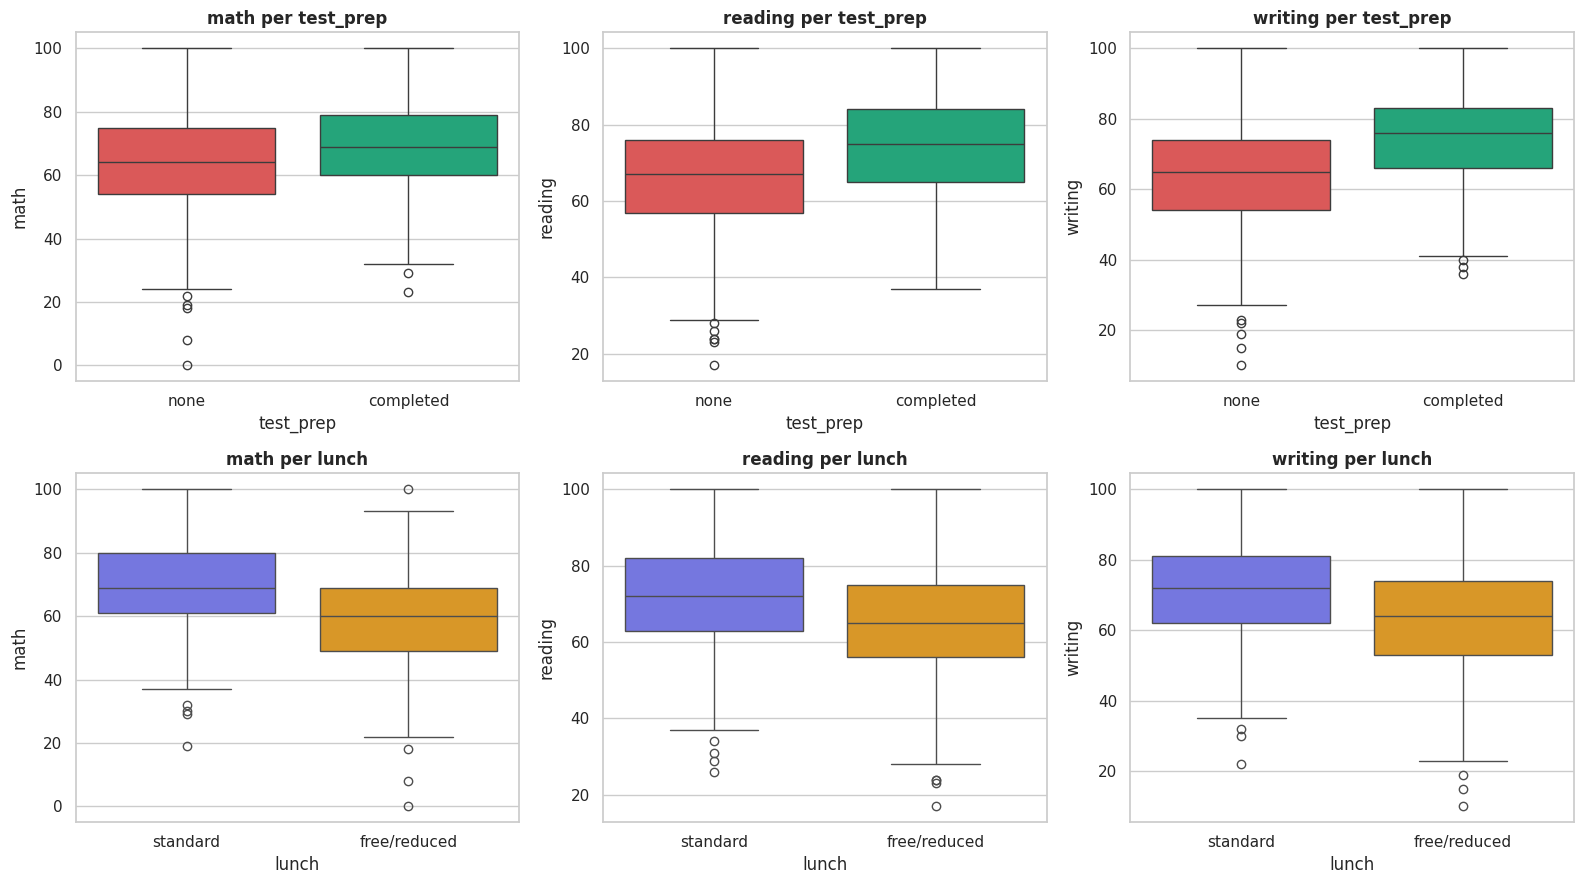

In [8]:
import os
os.makedirs('images', exist_ok=True)
numeric_cols = ['math', 'reading', 'writing']

# 1. Heatmap
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True)
ax.set_title('Correlation Matrix Skor', fontweight='bold')
plt.tight_layout()
plt.savefig('images/heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Scatter reading vs writing
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x='reading', y='writing', hue='test_prep',
                palette={'none': '#EF4444', 'completed': '#10B981'},
                s=60, alpha=0.7, edgecolor='black', ax=ax)
ax.set_title('Reading vs Writing Score', fontweight='bold')
plt.tight_layout()
plt.savefig('images/scatter.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Boxplot per kelompok
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x='test_prep', y=col, hue='test_prep', legend=False,
                palette={'none': '#EF4444', 'completed': '#10B981'}, ax=axes[0, j])
    axes[0, j].set_title(f'{col} per test_prep', fontweight='bold')
    sns.boxplot(data=df, x='lunch', y=col, hue='lunch', legend=False,
                palette={'standard': '#6366F1', 'free/reduced': '#F59E0B'}, ax=axes[1, j])
    axes[1, j].set_title(f'{col} per lunch', fontweight='bold')
plt.tight_layout()
plt.savefig('images/boxplot_kelompok.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
!zip -r images.zip images
from google.colab import files
files.download('images.zip')

updating: images/ (stored 0%)
updating: images/scatter.png (deflated 3%)
updating: images/boxplot_kelompok.png (deflated 25%)
updating: images/heatmap.png (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
print("=== RATA-RATA SKOR per test_prep ===")
print(df.groupby('test_prep')[numeric_cols].mean().round(2))
print("\n=== RATA-RATA SKOR per lunch ===")
print(df.groupby('lunch')[numeric_cols].mean().round(2))
print("\n=== RATA-RATA SKOR per gender ===")
print(df.groupby('gender')[numeric_cols].mean().round(2))
print("\n=== RATA-RATA avg_score per parent_edu ===")
print(df.groupby('parent_edu')['avg_score'].mean().round(2).sort_values())

=== RATA-RATA SKOR per test_prep ===
            math  reading  writing
test_prep                         
completed  69.70    73.89    74.42
none       64.08    66.53    64.50

=== RATA-RATA SKOR per lunch ===
               math  reading  writing
lunch                                
free/reduced  58.92    64.65    63.02
standard      70.03    71.65    70.82

=== RATA-RATA SKOR per gender ===
         math  reading  writing
gender                         
female  63.63    72.61    72.47
male    68.73    65.47    63.31

=== RATA-RATA avg_score per parent_edu ===
parent_edu
high school           63.10
some high school      65.11
some college          68.48
associate's degree    69.57
bachelor's degree     71.92
master's degree       73.60
Name: avg_score, dtype: float64


In [11]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

order = ['some high school', 'high school', 'some college',
         "associate's degree", "bachelor's degree", "master's degree"]
avg_edu = df.groupby('parent_edu')['avg_score'].mean().reindex(order).round(2)

fig = make_subplots(rows=1, cols=2,
                    subplot_titles=('Reading vs Writing Score',
                                    'Rata-rata Skor per Pendidikan Orang Tua'))

for prep, color in [('none', '#EF4444'), ('completed', '#10B981')]:
    sub = df[df['test_prep'] == prep]
    fig.add_trace(go.Scatter(x=sub['reading'], y=sub['writing'], mode='markers',
                             name=f'Test prep: {prep}',
                             marker=dict(color=color, opacity=0.6)), row=1, col=1)

fig.add_trace(go.Bar(x=avg_edu.index, y=avg_edu.values,
                     marker_color='#6366F1', showlegend=False), row=1, col=2)

fig.update_xaxes(title_text='Reading', row=1, col=1)
fig.update_yaxes(title_text='Writing', row=1, col=1)
fig.update_yaxes(title_text='Rata-rata skor', row=1, col=2)
fig.update_layout(height=500, width=1100, title_text='Students Performance Dashboard')
fig.show()

## Insight

1. **Data bersih dan distribusi simetris.** Tidak ada missing value atau duplikat pada 1000 baris. Mean dan median ketiga skor hampir sama (math 66,09 vs 66,0), dan semua outlier ada di sisi bawah (math 8, reading 6, writing 5).

2. **Test prep berkaitan dengan skor lebih tinggi.** Siswa yang menyelesaikan test prep unggul di semua mata ujian: math 69,70 vs 64,08, reading 73,89 vs 66,53, writing 74,42 vs 64,50. Hanya 35,8% siswa yang mengikutinya.

3. **Tipe makan siang berkaitan dengan skor.** Siswa lunch standard unggul atas free/reduced: math 70,03 vs 58,92 (selisih terbesar), reading 71,65 vs 64,65, writing 70,82 vs 63,02. Ini korelasi, bukan sebab-akibat.

4. **Pola gender berbeda antar mata ujian.** Perempuan lebih tinggi di reading (72,61 vs 65,47) dan writing (72,47 vs 63,31), sedangkan laki-laki lebih tinggi di math (68,73 vs 63,63).

5. **Korelasi antar skor kuat.** Reading–writing 0,955, math–reading 0,818, math–writing 0,803. Rata-rata skor juga naik seiring pendidikan orang tua, dari 63,10 (high school) ke 73,60 (master's degree).

## Hipotesis untuk Milestone 2 (Modul 10)

- **H1 (t-test independen):** Rata-rata skor writing siswa yang menyelesaikan test prep berbeda dari yang tidak mengikutinya.
- **H2 (t-test independen):** Rata-rata skor math siswa dengan lunch standard berbeda dari free/reduced.
- **H3 (ANOVA):** Rata-rata skor rata-rata (avg_score) berbeda antar tingkat pendidikan orang tua.